# Predicción de deserción estudiantil

**Objetivo:** predecir si un estudiante de educación superior va a **desertar** (*Dropout*), usando sus datos de matrícula y su rendimiento en el primer año.

Dataset: [Predict Students' Dropout and Academic Success](https://archive.ics.uci.edu/dataset/697) (UCI, id 697). 4.424 estudiantes de un instituto politécnico de Portugal, 36 variables. El target original tiene 3 clases (`Dropout`, `Enrolled`, `Graduate`); aquí lo convertimos en un problema **binario**: deserta (1) / no deserta (0).

Contenido:
1. Preparación de datos
2. EDA
3. Importancia de features
4. Selección de modelo y ajuste de parámetros
5. Evaluación final en test

In [23]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

## 1. Preparación de datos

El CSV usa `;` como separador. Los nombres de columna tienen espacios, paréntesis y apóstrofes (`Mother's qualification`, `Curricular units 1st sem (grade)`), así que los normalizamos a `snake_case`.

In [24]:
def clean_column(name):
    name = name.strip().lower().replace("'", "")
    return re.sub(r'[^a-z0-9]+', '_', name).strip('_')

df = pd.read_csv('data/data.csv', sep=';', encoding='utf-8-sig')
df.columns = [clean_column(c) for c in df.columns]
df = df.rename(columns={'status': 'target'})  # algunas copias del CSV la llaman 'Status'

df.shape

(4424, 37)

In [25]:
df.head()

,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nacionality,mothers_qualification,fathers_qualification,...,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [26]:
df.dtypes.value_counts()

int64      29
float64     7
str         1
Name: count, dtype: int64

In [27]:
# Valores faltantes
df.isnull().sum().sum()

np.int64(0)

No hay valores faltantes. Todas las variables son numéricas: las categóricas (curso, modo de postulación, ocupación de los padres, etc.) vienen codificadas como enteros. Los modelos de árboles manejan bien estos códigos, así que las dejamos así.

## 2. EDA

### Variable objetivo

In [28]:
df['target'].value_counts(normalize=True).round(3)

target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64

In [29]:
df['dropout'] = (df['target'] == 'Dropout').astype(int)
del df['target']

df['dropout'].mean().round(3)

np.float64(0.321)

Un **32%** de los estudiantes deserta. Las clases están algo desbalanceadas, por eso usamos **ROC AUC** como métrica (no depende de un umbral y funciona bien con desbalance) y un split **estratificado**, para mantener la misma proporción de desertores en train, validación y test.

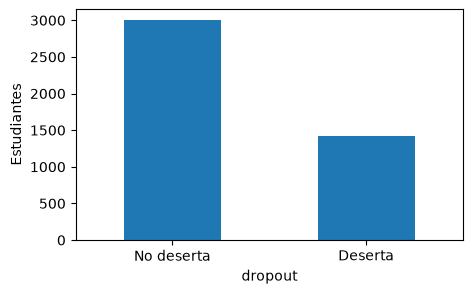

In [30]:
fig, ax = plt.subplots(figsize=(5, 3))
df['dropout'].value_counts().plot(kind='bar', ax=ax)
ax.set_xticklabels(['No deserta', 'Deserta'], rotation=0)
ax.set_ylabel('Estudiantes')
plt.show()

### Rangos de las variables numéricas

In [31]:
df.describe().T[['min', 'mean', 'max']].round(2)

,min,mean,max
marital_status,1.00,1.18,6.00
application_mode,1.00,18.67,57.00
application_order,0.00,1.73,9.00
course,33.00,8856.64,9991.00
daytime_evening_attendance,0.00,0.89,1.00
previous_qualification,1.00,4.58,43.00
previous_qualification_grade,95.00,132.61,190.00
nacionality,1.00,1.87,109.00
mothers_qualification,1.00,19.56,44.00
fathers_qualification,1.00,22.28,44.00


### Tasa de deserción por variables binarias

Comparamos la tasa de deserción de cada grupo contra la tasa global (32%).

In [32]:
binary = ['tuition_fees_up_to_date', 'scholarship_holder', 'debtor',
          'gender', 'displaced', 'international', 'daytime_evening_attendance']

global_rate = df['dropout'].mean()
for col in binary:
    rates = df.groupby(col)['dropout'].mean().round(3)
    print(col, dict(rates))

tuition_fees_up_to_date {0: np.float64(0.866), 1: np.float64(0.247)}
scholarship_holder {0: np.float64(0.387), 1: np.float64(0.122)}
debtor {0: np.float64(0.283), 1: np.float64(0.62)}
gender {0: np.float64(0.251), 1: np.float64(0.451)}
displaced {0: np.float64(0.376), 1: np.float64(0.276)}
international {0: np.float64(0.322), 1: np.float64(0.291)}
daytime_evening_attendance {0: np.float64(0.429), 1: np.float64(0.308)}


- Los estudiantes **sin la matrícula al día** (`tuition_fees_up_to_date=0`) desertan muchísimo más que el resto.
- Los **deudores** (`debtor=1`) también tienen una tasa muy superior.
- Los **becados** (`scholarship_holder=1`) desertan bastante menos.

### Rendimiento académico vs deserción

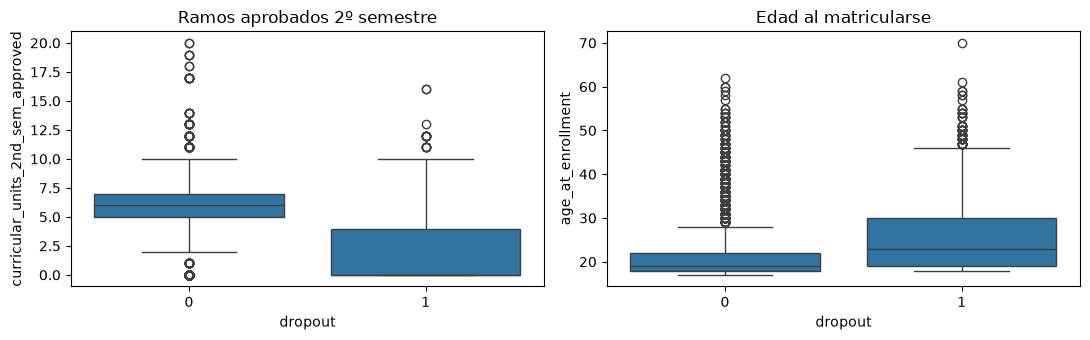

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(data=df, x='dropout', y='curricular_units_2nd_sem_approved', ax=axes[0])
sns.boxplot(data=df, x='dropout', y='age_at_enrollment', ax=axes[1])
axes[0].set_title('Ramos aprobados 2º semestre')
axes[1].set_title('Edad al matricularse')
plt.tight_layout()
plt.show()

Los desertores aprueban muchos menos ramos y tienden a matricularse a mayor edad.

## 3. Importancia de features

**Correlación** con el target (relaciones lineales) e **información mutua** (cualquier tipo de dependencia).

In [34]:
df.corr()['dropout'].drop('dropout').sort_values(key=abs, ascending=False).head(10).round(3)

curricular_units_2nd_sem_grade      -0.572
curricular_units_2nd_sem_approved   -0.570
curricular_units_1st_sem_grade      -0.481
curricular_units_1st_sem_approved   -0.479
tuition_fees_up_to_date             -0.429
age_at_enrollment                    0.254
scholarship_holder                  -0.245
debtor                               0.229
gender                               0.204
application_mode                     0.198
Name: dropout, dtype: float64

In [35]:
features = df.drop(columns='dropout')
mi = mutual_info_classif(features, df['dropout'], random_state=1)
pd.Series(mi, index=features.columns).sort_values(ascending=False).head(10).round(3)

curricular_units_2nd_sem_approved       0.204
curricular_units_2nd_sem_grade          0.190
curricular_units_1st_sem_approved       0.171
curricular_units_1st_sem_grade          0.148
tuition_fees_up_to_date                 0.092
curricular_units_2nd_sem_evaluations    0.068
age_at_enrollment                       0.051
application_mode                        0.047
curricular_units_1st_sem_evaluations    0.046
course                                  0.041
dtype: float64

Las variables más informativas son el **rendimiento académico** (ramos aprobados y notas de ambos semestres) y la situación **financiera** (matrícula al día). Las variables macroeconómicas (desempleo, inflación, PIB) aportan poco.

## 4. Selección de modelo

Split 60% / 20% / 20% estratificado.

In [36]:
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1, stratify=df['dropout'])
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1, stratify=df_full_train['dropout'])

y_train = df_train.pop('dropout').values
y_val = df_val.pop('dropout').values
y_test = df_test.pop('dropout').values

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))
X_val = dv.transform(df_val.to_dict(orient='records'))

len(df_train), len(df_val), len(df_test)

(2654, 885, 885)

In [37]:
def auc(model):
    return roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])

### 4.1 Regresión logística (baseline)

Se escalan las variables porque la regresión logística es sensible a la escala. Ajustamos la regularización `C`.

In [38]:
for C in [0.01, 0.1, 1, 10]:
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
    lr.fit(X_train, y_train)
    print(C, round(auc(lr), 4))

0.01 0.9145
0.1 0.9207
1 0.9205
10 0.9204


### 4.2 Árbol de decisión

Ajustamos `max_depth` y `min_samples_leaf`.

In [39]:
scores = []
for d in [3, 4, 5, 6, 8, 10]:
    for leaf in [1, 5, 10, 20, 50]:
        dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, random_state=1)
        dt.fit(X_train, y_train)
        scores.append((d, leaf, auc(dt)))

pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'auc']) \
    .sort_values('auc', ascending=False).head()

,max_depth,min_samples_leaf,auc
19,6,50,0.903972
24,8,50,0.903641
29,10,50,0.903192
14,5,50,0.902068
18,6,20,0.900234


### 4.3 Random forest

Ajustamos `max_depth` y `n_estimators`.

In [40]:
scores = []
for d in [5, 10, 15, None]:
    for n in [50, 100, 200]:
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        scores.append((d, n, auc(rf)))

pd.DataFrame(scores, columns=['max_depth', 'n_estimators', 'auc']) \
    .sort_values('auc', ascending=False).head()

,max_depth,n_estimators,auc
6,15.0,50,0.917693
11,NaN,200,0.917368
10,NaN,100,0.916474
5,10.0,200,0.916430
9,NaN,50,0.915291


### 4.4 XGBoost

Ajustamos `max_depth`, `learning_rate` (eta) y número de árboles.

In [41]:
scores = []
for d in [3, 4, 5, 6]:
    for eta in [0.05, 0.1]:
        for n in [100, 200, 300]:
            xgb_model = XGBClassifier(n_estimators=n, learning_rate=eta,
                                      max_depth=d, random_state=1)
            xgb_model.fit(X_train, y_train)
            scores.append((d, eta, n, auc(xgb_model)))

df_xgb = pd.DataFrame(scores, columns=['max_depth', 'eta', 'n_estimators', 'auc'])
df_xgb.sort_values('auc', ascending=False).head()

,max_depth,eta,n_estimators,auc
7,4,0.05,200,0.921481
8,4,0.05,300,0.921094
13,5,0.05,200,0.920608
12,5,0.05,100,0.920367
18,6,0.05,100,0.920151


### 4.5 Comparación

Mejor configuración de cada familia, en validación:

In [42]:
best = {
    'Regresión logística': make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)),
    'Árbol de decisión': DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=1),
    'Random forest': RandomForestClassifier(n_estimators=50, max_depth=15, random_state=1, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=1),
}

results = {}
for name, model in best.items():
    model.fit(X_train, y_train)
    results[name] = round(auc(model), 4)

pd.Series(results).sort_values(ascending=False)

XGBoost                0.9215
Regresión logística    0.9207
Random forest          0.9177
Árbol de decisión      0.9040
dtype: float64

**Modelo elegido: XGBoost** (`max_depth=4`, `learning_rate=0.05`, `n_estimators=200`). Tiene el mejor AUC en validación. La regresión logística queda muy cerca, lo que indica que gran parte de la señal es casi lineal (ramos aprobados, matrícula al día), pero XGBoost captura algo más sin necesidad de escalar las variables.

Importancia de features según el modelo elegido:

In [43]:
xgb_model = best['XGBoost']
pd.Series(xgb_model.feature_importances_, index=dv.get_feature_names_out()) \
    .sort_values(ascending=False).head(10).round(3)

curricular_units_2nd_sem_approved    0.234
tuition_fees_up_to_date              0.110
curricular_units_1st_sem_enrolled    0.063
curricular_units_1st_sem_approved    0.045
curricular_units_2nd_sem_credited    0.039
curricular_units_2nd_sem_grade       0.037
age_at_enrollment                    0.030
debtor                               0.029
curricular_units_2nd_sem_enrolled    0.027
scholarship_holder                   0.025
dtype: float32

## 5. Evaluación final

Reentrenamos el modelo elegido con **train + validación** y lo evaluamos una sola vez en **test**. Esto es lo mismo que hace `train.py`.

In [44]:
y_full_train = np.concatenate([y_train, y_val])
df_full = pd.concat([df_train, df_val])

final = make_pipeline(
    DictVectorizer(sparse=False),
    XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=1),
)
final.fit(df_full.to_dict(orient='records'), y_full_train)

y_pred = final.predict_proba(df_test.to_dict(orient='records'))[:, 1]
round(roc_auc_score(y_test, y_pred), 4)

0.9164

El AUC en test es similar al de validación: el modelo generaliza y no hay señales de overfitting por haber ajustado parámetros sobre validación.